# Basic Data Visualisation, How to make bar charts in Python: Exercise solution

The following code relates to the **Making bar charts in Python** script in the
**Basic Data Visualisation** learning resource on the [Analysis for Action]([PLACEHOLDER])
platform.

This is the code used to produce the exercise solution from the **Making bar charts in Python** script. Compare your code and output against the code and output produced here to see how well you did. Note that your code and output do not need to match the solution exactly to be considered correct!

Can you think of any other ways of making the bar chart more accessible?

The bar chart should:

-   Show the size of vulnerable populations in Argentina, Malawi, Nepal, and the United Kingdom in the year 1997
-   Be formatted so that:
    -   The y-axis label is: Country 
    -   The x-axis label is: Vulnerable Population (Millions) 
    -   The text size of the axis titles is 16
    -   Horizontal gridlines are removed
    -   The largest bar is HEX code #324028, the rest are HEX code #D4DDD6
    -   The width of the bars is 0.6
    -   The bars are ordered from largest to smallest
    -   The y-axis uses millions suffix (for example an axis break with a value of 6000000 would show as 6M)
    -   The chart is exported as an .svg file with the file name:
        vuln_pop_partner_countries 
    -   The chart is saved to the exercise_outputs folder
    -   The .svg chart has an aspect ratio of 16:9

# Setup

In [3]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

os.chdir("D:/repos/analysis-for-action")

# Load the dataset
vuln = pd.read_csv("learning_resources/data/vulnerable.csv")

# Preparing the dataframe

In [4]:
# Prepare the data to make it suitable for a bar chart

vuln_1997_partner_countries = (
    vuln.query('year == 1997 and country in ["Argentina", "Malawi", "Nepal", "United Kingdom"]')
        [["vulnerable_pop", "country"]]
        .nlargest(4, "vulnerable_pop")
)

vuln_focus_1997 = vuln_1997_partner_countries.copy()

vuln_focus_1997['highlight'] = vuln_focus_1997['vulnerable_pop'] == vuln_focus_1997['vulnerable_pop'].max()

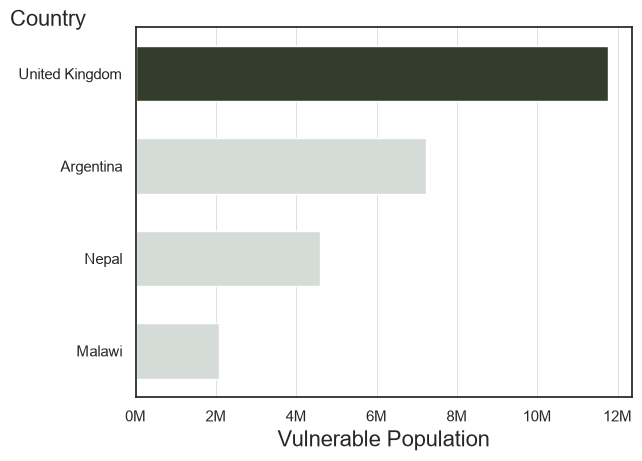

In [5]:
# Set the theme for the plot
sns.set_theme(style="white")

vuln_bar_focus_chart = sns.barplot(
    data = vuln_focus_1997,
    x = "vulnerable_pop",
    y = "country",
    hue = "highlight",
    palette = {True: "#324028", False: "#D4DDD6"},
    # Change bar width to 0.6
    width = 0.6
)
# Set the gridlines for the x-axis
vuln_bar_focus_chart.xaxis.grid(True, which='major', linestyle='-', linewidth=0.5, color='lightgrey')
# Remove scientific notation
vuln_bar_focus_chart.ticklabel_format(axis='x', style='plain')
# Add axis titles
vuln_bar_focus_chart.set_xlabel("Vulnerable Population", fontsize=16)
vuln_bar_focus_chart.set_ylabel("Country", fontsize=16)
# Set y-axis title to be horizontal
vuln_bar_focus_chart.yaxis.label.set_rotation(0)
vuln_bar_focus_chart.yaxis.label.set_horizontalalignment('right')
vuln_bar_focus_chart.yaxis.label.set_verticalalignment('center')
vuln_bar_focus_chart.yaxis.set_label_coords(-0.1, 1.02)
# Set x-axis labels to be in millions
vuln_bar_focus_chart.get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, pos: f"{int(x/1000000)}M"))
# Remove legend
vuln_bar_focus_chart.get_legend().remove()

In [31]:
# Export the plot as an SVG file to the exercise_outputs folder
# Expand the plot to extend further left to accommodate the y-axis title and labels
vuln_bar_focus_chart.figure.subplots_adjust(left=0.2)
vuln_bar_focus_chart.figure.savefig("learning_resources/outputs_and_reporting/data_visualisation/basic_data_visualisation/python/exercise_outputs/vuln_bar_solution.svg", format="svg")